Loading datasets...

Original dataset distribution:
label
Fake    23481
Real    21417
Name: count, dtype: int64

DATASET PREPARATION COMPLETED
Unique articles: 39103

Class distribution:
label
Real    21196
Fake    17907
Name: count, dtype: int64

TEXT PREPROCESSING COMPLETED

Original article:
Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had ju

Cleaned article:
donald trump sends out embarrassing new year s eve message this is disturbing donald trump just couldn t wish all americans a happy new year and leave it at that instead he had to give a shout out to his enemies haters and the very dishonest fake news media the former reality show star had just one 

TRAINING EXAMPLES
Total examples: 155518
Real    84782
Fake    70736
Name: count, d

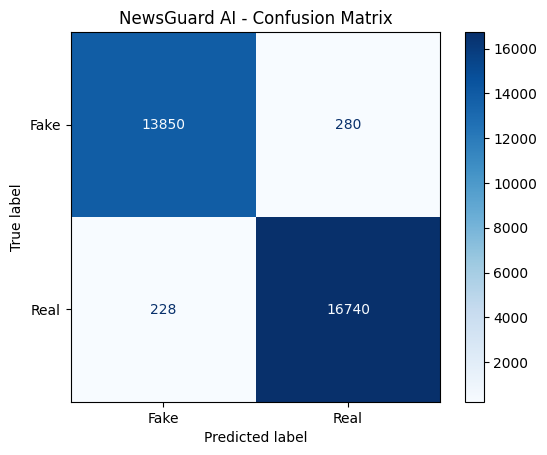

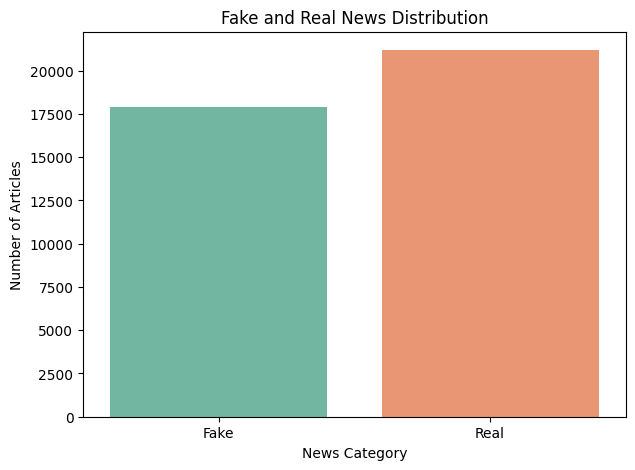


SAMPLE NEWS PREDICTIONS
-----------------------

Article: The government announced a new education policy to improve schools across the country.
Prediction: Fake
Confidence: 53.38%

Article: Scientists have discovered a new method to produce clean energy using solar technology.
Prediction: Fake
Confidence: 63.27%

Article: A celebrity secretly revealed that aliens control the government and everyone must believe it.
Prediction: Fake
Confidence: 99.21%

NOTEBOOK MODEL SAVED SUCCESSFULLY!
Location: C:\Users\ANJANA\Desktop\AI-ML-Internship\Fake-News-WebApp\backend\newsguard_model_notebook.pkl

NEWSGUARD AI - PROJECT COMPLETED
Dataset articles: 39103
Training examples: 124420
Testing examples: 31098
Accuracy: 98.37%
Precision: 98.35%
Recall: 98.66%
F1 Score: 98.51%

Technologies Used:
Python, Pandas, NLTK, Scikit-learn, TF-IDF,
Logistic Regression, Matplotlib, Seaborn

NewsGuard AI execution completed!


In [1]:

# ============================================================
# NEWSGUARD AI - FAKE NEWS CLASSIFICATION
# NLP | NLTK | TF-IDF | LOGISTIC REGRESSION
# ============================================================

import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from nltk.tokenize import RegexpTokenizer

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. DATASET LOADING
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

FAKE_PATH = BASE_DIR / "Fake.csv"
REAL_PATH = BASE_DIR / "True.csv"

print("Loading datasets...")

fake_df = pd.read_csv(FAKE_PATH)
real_df = pd.read_csv(REAL_PATH)

fake_df["label"] = "Fake"
real_df["label"] = "Real"

df = pd.concat([fake_df, real_df], ignore_index=True)

print("\nOriginal dataset distribution:")
print(df["label"].value_counts())

# ------------------------------------------------------------
# 2. DATASET PREPARATION
# ------------------------------------------------------------

df["title"] = df["title"].fillna("").astype(str).str.strip()
df["text"] = df["text"].fillna("").astype(str).str.strip()

df = df[
    (df["title"].str.len() > 0) |
    (df["text"].str.len() > 0)
].copy()

df["original_article"] = (
    df["title"] + " " + df["text"]
).str.strip()

df = df.drop_duplicates(
    subset=["original_article"]
).reset_index(drop=True)

print("\nDATASET PREPARATION COMPLETED")
print("Unique articles:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts())

# ------------------------------------------------------------
# 3. NLTK TEXT PREPROCESSING
# ------------------------------------------------------------

tokenizer = RegexpTokenizer(r"[A-Za-z]+")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\*\*.*?\*\*", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"\b\w*\d\w*\b", " ", text)

    return " ".join(tokenizer.tokenize(text))

df["cleaned_article"] = df["original_article"].apply(clean_text)

print("\nTEXT PREPROCESSING COMPLETED")
print("\nOriginal article:")
print(df["original_article"].iloc[0][:300])

print("\nCleaned article:")
print(df["cleaned_article"].iloc[0][:300])

# ------------------------------------------------------------
# 4. CREATE DIFFERENT ARTICLE LENGTHS
# ------------------------------------------------------------

samples = []
labels = []
groups = []

for article_id, row in df.iterrows():

    title = row["title"]
    text = row["text"]
    label = row["label"]

    full_article = (title + " " + text).strip()

    if title:
        samples.append(title)
        labels.append(label)
        groups.append(article_id)

    if text:
        samples.append((title + " " + text[:300]).strip())
        labels.append(label)
        groups.append(article_id)

        samples.append((title + " " + text[:1000]).strip())
        labels.append(label)
        groups.append(article_id)

    if full_article:
        samples.append(full_article)
        labels.append(label)
        groups.append(article_id)

X = pd.Series(samples)
y = pd.Series(labels)
groups = pd.Series(groups)

print("\nTRAINING EXAMPLES")
print("Total examples:", len(X))
print(y.value_counts())

# ------------------------------------------------------------
# 5. TRAIN-TEST SPLIT
# ------------------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("\nTRAINING DATA:", len(X_train))
print("TESTING DATA:", len(X_test))

# ------------------------------------------------------------
# 6. WORD-LEVEL TF-IDF
# ------------------------------------------------------------

word_features = TfidfVectorizer(
    preprocessor=clean_text,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=150000,
    sublinear_tf=True
)

# ------------------------------------------------------------
# 7. CHARACTER-LEVEL TF-IDF
# ------------------------------------------------------------

char_features = TfidfVectorizer(
    preprocessor=clean_text,
    analyzer="char",
    ngram_range=(3, 5),
    min_df=3,
    max_features=100000,
    sublinear_tf=True
)

features = FeatureUnion([
    ("word", word_features),
    ("char", char_features)
])

# ------------------------------------------------------------
# 8. LOGISTIC REGRESSION MODEL
# ------------------------------------------------------------

model = Pipeline([
    ("tfidf", features),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

print("\nTraining NewsGuard AI model...")

model.fit(X_train, y_train)

print("Model training completed!")

# ------------------------------------------------------------
# 9. MODEL EVALUATION
# ------------------------------------------------------------

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, pos_label="Real")
recall = recall_score(y_test, predictions, pos_label="Real")
f1 = f1_score(y_test, predictions, pos_label="Real")

print("\nMODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, predictions))

# ------------------------------------------------------------
# 10. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    predictions,
    labels=["Fake", "Real"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("NewsGuard AI - Confusion Matrix")
plt.show()

# ------------------------------------------------------------
# 11. DATASET DISTRIBUTION GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["Fake", "Real"],
    palette="Set2",
    legend=False
)

plt.title("Fake and Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.show()

# ------------------------------------------------------------
# 12. SAMPLE NEWS PREDICTIONS
# ------------------------------------------------------------

test_articles = [
    "The government announced a new education policy to improve schools across the country.",
    "Scientists have discovered a new method to produce clean energy using solar technology.",
    "A celebrity secretly revealed that aliens control the government and everyone must believe it."
]

print("\nSAMPLE NEWS PREDICTIONS")
print("-----------------------")

for article in test_articles:

    prediction = model.predict([article])[0]
    probabilities = model.predict_proba([article])[0]

    probability_dict = dict(
        zip(model.classes_, probabilities)
    )

    print("\nArticle:", article)
    print("Prediction:", prediction)
    print(
        "Confidence:",
        f"{probability_dict[prediction] * 100:.2f}%"
    )

# ------------------------------------------------------------
# 13. SAVE NOTEBOOK MODEL SEPARATELY
# ------------------------------------------------------------

MODEL_PATH = BASE_DIR / "newsguard_model_notebook.pkl"

joblib.dump(model, MODEL_PATH)

print("\nNOTEBOOK MODEL SAVED SUCCESSFULLY!")
print("Location:", MODEL_PATH)

# ------------------------------------------------------------
# 14. FINAL PROJECT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("NEWSGUARD AI - PROJECT COMPLETED")
print("=" * 55)

print("Dataset articles:", len(df))
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

print("\nTechnologies Used:")
print("Python, Pandas, NLTK, Scikit-learn, TF-IDF,")
print("Logistic Regression, Matplotlib, Seaborn")

print("\nNewsGuard AI execution completed!")
